# Copper–Zinc Spread, Gold and US Equities: Mean Reversion, Macro Sensitivity and Predictability (1973–today)

## Research question
Copper and zinc are both industrial metals driven by global manufacturing demand, but copper is more tied to electrification/construction and zinc to galvanised steel. We want to know if their price spread is a stable, mean-reverting object, and if it is driven by safe-haven (gold) and risk-appetite (US equities) shocks? Do these findings hold across eras and for other metal pairs?

## Hypotheses
|  | Hypothesis | Test |
|---|---|---|
| **H1** | The log Cu/Zn ratio is mean-reverting (cointegrated), but its half-life and stability vary across eras. | ADF, KPSS, Engle–Granger, Johansen, rolling half-life, era split |
| **H2** | Spread changes load **positively on US equity returns** (risk-on favours copper over zinc) and **negatively / insignificantly on gold** (risk-off). | HAC regressions at 1/3/12-month horizons, rolling betas, lead/lag placebo |
| **H3** | That sensitivity is **regime-dependent** (stronger when equity volatility is high). | Interaction regression on an ex-ante vol regime, 2-state Markov-switching regression |
| **H4** | Gold and equity information adds **out-of-sample** predictive power for future spread changes beyond plain mean reversion. | Expanding-window walk-forward, OOS R², Clark–West tests, IC, cost-aware illustrative backtest with bootstrap CI |
| **H5** | Cu/Zn is not special: other LME metal pairs show similar (or very different) mean reversion and macro loadings. | Same tests on Cu/Al, Cu/Ni, Zn/Pb, Al/Zn, Ni/Zn |

## Data sources
| Data | Source | Notes |
|---|---|---|
| Copper, zinc, aluminium, lead, nickel, gold, crude oil — monthly **average** prices, nominal USD | **World Bank Commodity Markets "Pink Sheet"** (`CMO-Historical-Data-Monthly.xlsx`), <https://www.worldbank.org/en/research/commodity-markets> | teacher-suggested source; metals are LME prices, gold is LBMA/market price |
| S&P 500 (monthly average of daily closes) | Yahoo Finance `^GSPC` via `yfinance` (primary); fallback: Robert Shiller's monthly S&P series mirrored in the `datasets/s-and-p-500` GitHub repo | averaged to match the Pink Sheet's monthly-average convention |
| Cross-check: IMF copper & zinc | **FRED** series `PCOPPUSDM`, `PZINCUSDM` (IMF Primary Commodity Prices), <https://fred.stlouisfed.org> | teacher-suggested sources (IMF, FRED) |

Downloaded files are cached in `./data/` — **submit that folder together with the notebook** so the grader can rerun it even if a website changes (World Bank file URLs change every year; the notebook scrapes the current link and has fallbacks).

## References (explicitly reused ideas)
* Walk-forward / purged out-of-sample evaluation and Spearman-IC evaluation follow the style of the public solutions to the Kaggle *MITSUI&CO. Commodity Prediction Challenge* (<https://www.kaggle.com/competitions/mitsui-commodity-prediction-challenge>); that competition's data is not used here because it is no longer downloadable.
* Engle & Granger (1987), *Co-integration and error correction*, Econometrica. Johansen (1991), Econometrica.
* Newey & West (1987) HAC standard errors (via `statsmodels`).
* Campbell & Thompson (2008), *Predicting excess stock returns out of sample*, RFS (OOS R² vs historical mean).
* Clark & West (2007), *Approximately normal tests for equal predictive accuracy in nested models*, J. Econometrics.
* Hamilton (1989), Econometrica (Markov-switching regression, `statsmodels.tsa.MarkovRegression`).
* Politis & Romano (1994), stationary bootstrap (re-implemented below).
* Working (1960), *Note on the correlation of first differences of averages in a random chain*, Econometrica — why returns built from monthly **averages** are autocorrelated (relevant for §3).

All code below is my own, written for this project.

**Requirements:** `numpy pandas scipy statsmodels scikit-learn matplotlib openpyxl requests` (+ optional `yfinance`; `pip install yfinance` if missing). Runtime: about 1–3 minutes.

# Copper–Zinc Spread, Gold and US Equities: Mean Reversion, Macro Sensitivity and Predictability

## Research question
Copper and zinc are both industrial metals driven by global manufacturing demand, but copper is more tied to electrification/construction and zinc to galvanised steel. Is their price spread a stable, mean-reverting object, and is it driven by safe-haven (gold) and risk-appetite (US equities) shocks? Do these findings hold across eras and for other metal pairs?

## Hypotheses
| # | Hypothesis | Test |
|---|---|---|
| **H1** | The log Cu/Zn ratio is mean-reverting (cointegrated), but its half-life and stability vary across eras. | ADF, KPSS, Engle–Granger, Johansen, rolling half-life, era split |
| **H2** | Spread changes load **positively on US equity returns** (risk-on favours copper over zinc) and **negatively / insignificantly on gold** (risk-off). | HAC regressions at 1/3/12-month horizons, rolling betas, lead/lag placebo |
| **H3** | That sensitivity is **regime-dependent** (stronger when equity volatility is high). | Interaction regression on an ex-ante vol regime, 2-state Markov-switching regression |
| **H4** | Gold and equity information adds **out-of-sample** predictive power for future spread changes beyond plain mean reversion. | Expanding-window walk-forward, OOS R², Clark–West tests, IC, cost-aware illustrative backtest with bootstrap CI |
| **H5** | Cu/Zn is not special: other LME metal pairs show similar (or very different) mean reversion and macro loadings. | Same tests on Cu/Al, Cu/Ni, Zn/Pb, Al/Zn, Ni/Zn |

In [1]:
%pip install openpyxl


[notice] A new release of pip is available: 26.2.2 -> 26.3
[notice] To update, run: pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


In [34]:
## Preparation

from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
import statsmodels.api as sm
from statsmodels.tsa.stattools import adfuller, kpss, coint
from statsmodels.tsa.vector_ar.vecm import coint_johansen
from statsmodels.regression.rolling import RollingOLS
from sklearn.linear_model import Ridge
from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline

SEED = 1
rng = np.random.default_rng(SEED)

## 1. Data

1. World Bank Pink Sheet: monthly average prices.
2. Git: monthly average of S&P 500 index.

In [25]:
# World Bank Pink Sheet
cmo = pd.read_excel(
    "CMO_monthly.xlsx",
    sheet_name="Monthly Prices",
    header=4
)

cmo.rename(columns={cmo.columns[0]: "Date"}, inplace=True)
cmo["Date"] = pd.to_datetime(cmo["Date"], format="%YM%m")
cmo = cmo[['Date', 'Zinc', 'Copper', 'Gold', 'Aluminum', 'Lead', 'Nickel', 'Crude oil, average']]
cmo

/tmp/ipykernel_22056/1288890940.py:8: Pandas4Warning: The inplace keyword in DataFrame.rename is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  cmo.rename(columns={cmo.columns[0]: "Date"}, inplace=True)


,Date,Zinc,Copper,Gold,Aluminum,Lead,Nickel,"Crude oil, average"
0,NaT,($/mt),($/mt),($/troy oz),($/mt),($/mt),($/mt),($/bbl)
1,1960-01-01,261,715,35,511,206,1631,1.6
2,1960-02-01,245,728,35,511,204,1631,1.6
3,1960-03-01,249,685,35,511,210,1631,1.6
4,1960-04-01,255,723,35,511,214,1631,1.6
...,...,...,...,...,...,...,...,...
798,2026-06-01,3539,13552,4228,3439,1946,17588,81.7
799,2026-07-01,3599,13543,4073,3161,1842,16651,79.8
800,2026-08-01,3875,14326,4411,3251,1855,16751,84.4
801,2026-09-01,4021,14474,4319,3283,1873,16324,102.3


In [26]:
# S&P 500
snp = pd.read_csv("https://raw.githubusercontent.com/datasets/s-and-p-500/main/data/data.csv",
    parse_dates=["Date"])
snp = snp[["Date", "SP500"]]
snp = snp[snp["Date"] >= "1960-01-01"]
snp

,Date,SP500
1068,1960-01-01,58.03
1069,1960-02-01,55.78
1070,1960-03-01,55.02
1071,1960-04-01,55.73
1072,1960-05-01,55.22
...,...,...
1864,2026-05-01,7412.55
1865,2026-06-01,7450.03
1866,2026-07-01,7481.34
1867,2026-08-01,7711.32


In [28]:
df = pd.merge(cmo, snp, on="Date", how="inner")
for col in df.columns:
    if col != 'Date':
        df[col] = pd.to_numeric(df[col], errors='coerce')
df['Spread ln(cu) - ln(zn)'] = np.log(df['Copper']) - np.log(df['Zinc']) 
df

,Date,Zinc,Copper,Gold,Aluminum,Lead,Nickel,"Crude oil, average",SP500,Spread ln(cu) - ln(zn)
0,1960-01-01,261,715,35,511,206,1631,1.6,58.03,1.007762
1,1960-02-01,245,728,35,511,204,1631,1.6,55.78,1.089043
2,1960-03-01,249,685,35,511,210,1631,1.6,55.02,1.011966
3,1960-04-01,255,723,35,511,214,1631,1.6,55.73,1.042146
4,1960-05-01,254,685,35,511,213,1631,1.6,55.22,0.992085
...,...,...,...,...,...,...,...,...,...,...
796,2026-05-01,3482,13543,4587,3666,1991,18806,100.4,7412.55,1.358263
797,2026-06-01,3539,13552,4228,3439,1946,17588,81.7,7450.03,1.342690
798,2026-07-01,3599,13543,4073,3161,1842,16651,79.8,7481.34,1.325214
799,2026-08-01,3875,14326,4411,3251,1855,16751,84.4,7711.32,1.307530


Text(0, 0.5, 'Correlation')

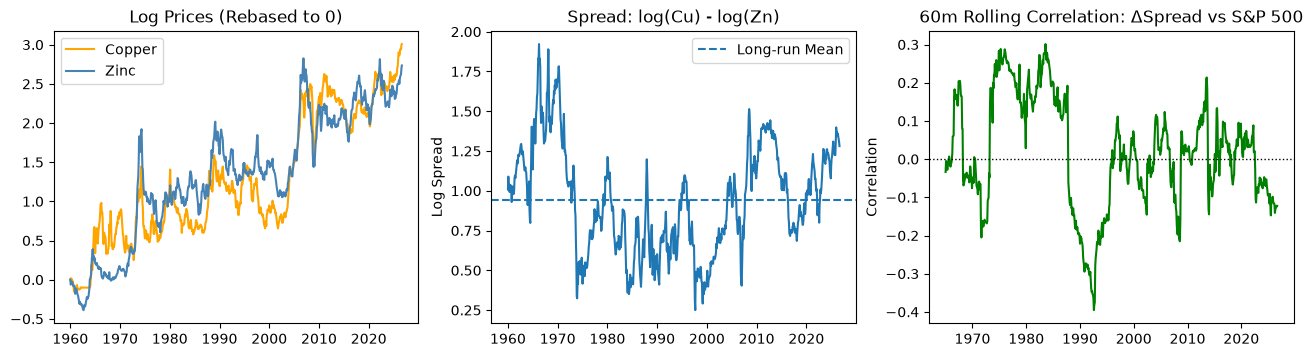

In [21]:
fig, ax = plt.subplots(1, 3, figsize=(16, 3.8))

ax[0].plot(df['Date'], np.log(df['Copper']) - np.log(df['Copper'].iloc[0]), label='Copper', color='orange')
ax[0].plot(df['Date'], np.log(df['Zinc']) - np.log(df['Zinc'].iloc[0]), label='Zinc', color='steelblue')
ax[0].set_title("Log Prices (Rebased to 0)")
ax[0].legend()

ax[1].plot(df['Date'], df['Spread'])
ax[1].axhline(df['Spread'].mean(), linestyle='--', label='Long-run Mean')
ax[1].set_title("Spread: log(Cu) - log(Zn)")
ax[1].set_ylabel("Log Spread")
ax[1].legend()

spread_ret = df['Spread'].diff()
equity_ret = df['SP500'].pct_change()  # equivalent to log return for small changes
rolling_corr = spread_ret.rolling(60).corr(equity_ret)
ax[2].plot(df['Date'], rolling_corr, color='green')
ax[2].axhline(0, color='black', linestyle=':', linewidth=1) # zero line for reference
ax[2].set_title("60m Rolling Correlation: ΔSpread vs S&P 500")
ax[2].set_ylabel("Correlation")

In [ ]:
NAMES = {"Copper": "cu", "Zinc": "zn", "Gold": "gold", "SP500": "eq",
         "Aluminum": "al", "Aluminium": "al", "Lead": "pb", "Nickel": "ni", "Oil": "oil"}
raw = df.rename(columns=NAMES).drop(columns=["Spread"], errors="ignore")
raw["Date"] = pd.to_datetime(raw["Date"])
raw = raw.set_index("Date").sort_index().apply(pd.to_numeric, errors="coerce")
raw = raw.dropna(subset=["cu", "zn", "gold", "eq"])
lev = np.log(raw)                                          # log levels (monthly averages)
rets = lev[["cu", "zn", "gold", "eq"]].diff().dropna()    # monthly log returns
s = lev["cu"] - lev["zn"]                                  # log Cu/Zn ratio = "spread"
rets["ds"] = rets["cu"] - rets["zn"]                       # spread change

,cu,zn,gold,eq,ds
Date,,,,,
1960-02-01,0.018019,-0.063262,0.000000,-0.039545,0.081281
1960-03-01,-0.060882,0.016195,0.000000,-0.013719,-0.077077
1960-04-01,0.053990,0.023811,0.000000,0.012822,0.030180
1960-05-01,-0.053990,-0.003929,0.000000,-0.009193,-0.050061
1960-06-01,0.010167,-0.015873,0.000000,0.036277,0.026040
...,...,...,...,...,...
2026-05-01,0.044697,0.034476,-0.028794,0.063425,0.010221
2026-06-01,0.000664,0.016237,-0.081497,0.005044,-0.015573
2026-07-01,-0.000664,0.016812,-0.037349,0.004194,-0.017476


## 2. H1 – Is the Cu/Zn spread mean-reverting?

If both metals share a common global-demand trend, `log Cu − β·log Zn` should be stationary. We combine ADF (H0: unit root), KPSS (H0: stationary — the opposite null, so agreement is stronger evidence), Engle–Granger and Johansen cointegration tests, and the AR(1) half-life with a residual-bootstrap CI. Because structural change is the main risk for any pairs idea, we also track a rolling ADF p-value / half-life and split the sample into eras.

In [36]:
def halflife(x):
    x = np.asarray(x, float); y, X = x[1:], sm.add_constant(x[:-1])
    b = np.linalg.lstsq(X, y, rcond=None)[0]; phi = b[1]
    return (-np.log(2) / np.log(phi)) if 0 < phi < 1 else np.inf, phi, b, y - X @ b

def boot_halflife(x, B=500):
    x = np.asarray(x, float); hl, phi, b, e = halflife(x); out = []
    for _ in range(B):
        ee = rng.choice(e, len(e)); xs = np.empty(len(e) + 1); xs[0] = x[0]
        for i in range(len(e)): xs[i + 1] = b[0] + b[1] * xs[i] + ee[i]
        out.append(halflife(xs)[0])
    return np.nanpercentile(np.minimum(out, 1e4), [5, 50, 95])

R = {}

adf = adfuller(s, regression="c", autolag="AIC"); kp = kpss(s, regression="c", nlags="auto")
eg = coint(lev["cu"], lev["zn"], trend="c", autolag="aic"); jo = coint_johansen(lev[["cu", "zn"]], det_order=0, k_ar_diff=2)
ols = sm.OLS(lev["cu"], sm.add_constant(lev["zn"])).fit(); hl, phi, *_ = halflife(s); ci = boot_halflife(s)
tab = pd.DataFrame({"statistic": [adf[0], kp[0], eg[0], jo.lr1[0]],
                    "p-value / crit.": [adf[1], kp[1], eg[1], f"5% crit={jo.cvt[0,1]:.2f}"],
                    "reading": ["p<0.05 ⇒ reject unit root", "p>0.05 ⇒ cannot reject stationarity", "p<0.05 ⇒ cointegrated", "trace>crit ⇒ rank ≥1"]},
                   index=["ADF (spread)", "KPSS (spread)", "Engle–Granger (Cu,Zn)", "Johansen trace (r=0)"])
display(tab.round(4))
print(f"Cointegrating slope (log Cu on log Zn): beta = {ols.params['zn']:.3f}  (β=1 ⇔ log-ratio spread)")
print(f"AR(1) phi = {phi:.4f}; half-life = {hl:.1f} months; bootstrap 5/50/95% = {np.round(ci, 1)} months")
R["H1"] = dict(adf_p=adf[1], kpss_p=kp[1], eg_p=eg[1], johansen_reject=bool(jo.lr1[0] > jo.cvt[0, 1]), beta=ols.params["zn"], halflife=hl, hl_ci=ci)

/tmp/ipykernel_22056/2484533048.py:16: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  adf = adfuller(s, regression="c", autolag="AIC"); kp = kpss(s, regression="c", nlags="auto")
/tmp/ipykernel_22056/2484533048.py:16: FutureWarning: kpss currently returns a plain tuple whose length and layout depends on the store argument (and which silently drops `lags` when store=True). In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning a KPSSResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  adf = adfuller(s, regression="c", autolag="AIC"); kp = kpss(s, regressio

,statistic,p-value / crit.,reading
ADF (spread),-2.0666,0.258144,p<0.05 ⇒ reject unit root
KPSS (spread),0.5877,0.023751,p>0.05 ⇒ cannot reject stationarity
"Engle–Granger (Cu,Zn)",-1.8327,0.613721,p<0.05 ⇒ cointegrated
Johansen trace (r=0),10.5140,5% crit=15.49,trace>crit ⇒ rank ≥1


Cointegrating slope (log Cu on log Zn): beta = 0.904  (β=1 ⇔ log-ratio spread)
AR(1) phi = 0.9842; half-life = 43.5 months; bootstrap 5/50/95% = [20.5 34.6 68.3] months


/tmp/ipykernel_22056/2776298925.py:4: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  rows.append((s.index[end - 1], adfuller(w, regression="c", autolag="AIC")[1], min(halflife(w)[0], 120)))
/tmp/ipykernel_22056/2776298925.py:4: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  rows.append((s.index[end - 1], adfuller(w, regression="c", autolag="AIC")[1], min(halflife(w)[0], 120

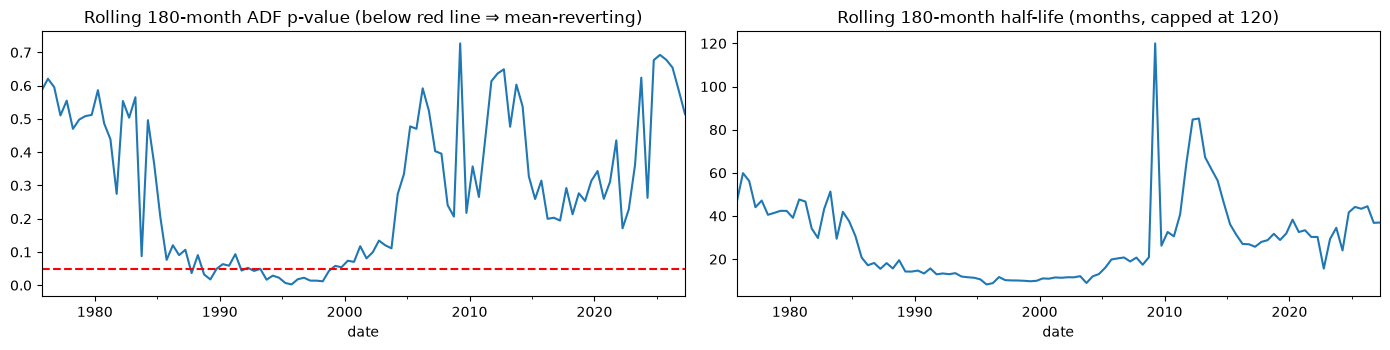

Share of rolling windows where a unit root is rejected at 5%: 17%


In [39]:
W, rows = 180, []
for end in range(W, len(s) + 1, 6):
    w = s.iloc[end - W:end]
    rows.append((s.index[end - 1], adfuller(w, regression="c", autolag="AIC")[1], min(halflife(w)[0], 120)))
roll = pd.DataFrame(rows, columns=["date", "adf_p", "half_life"]).set_index("date")
fig, ax = plt.subplots(1, 2, figsize=(14, 3.6))
roll["adf_p"].plot(ax=ax[0], title=f"Rolling {W}-month ADF p-value (below red line ⇒ mean-reverting)"); ax[0].axhline(.05, c="r", ls="--")
roll["half_life"].plot(ax=ax[1], title=f"Rolling {W}-month half-life (months, capped at 120)")
plt.tight_layout(); plt.show()
share = (roll["adf_p"] < .05).mean(); R["H1"]["share_stationary_windows"] = share
print(f"Share of rolling windows where a unit root is rejected at 5%: {share:.0%}")

In [ ]:
W, rows = CFG["roll_window"], []
for end in range(W, len(s) + 1, 6):
    w = s.iloc[end - W:end]
    rows.append((s.index[end - 1], adfuller(w, regression="c", autolag="AIC")[1], min(halflife(w)[0], 120)))
roll = pd.DataFrame(rows, columns=["date", "adf_p", "half_life"]).set_index("date")
fig, ax = plt.subplots(1, 2, figsize=(14, 3.6))
roll["adf_p"].plot(ax=ax[0], title=f"Rolling {W}-month ADF p-value (below red line ⇒ mean-reverting)"); ax[0].axhline(.05, c="r", ls="--")
roll["half_life"].plot(ax=ax[1], title=f"Rolling {W}-month half-life (months, capped at 120)")
plt.tight_layout(); plt.show()
share = (roll["adf_p"] < .05).mean(); R["H1"]["share_stationary_windows"] = share
print(f"Share of rolling windows where a unit root is rejected at 5%: {share:.0%}")

## 3. H2 – Do gold and US equities drive the spread?

HAC (Newey–West) regressions of spread changes on gold and equity returns; overlapping multi-month horizons need HAC. Three angles:

1. **Horizon regressions** (1, 3, 12 months): `Δs = a + b_eq·r_eq + b_gold·r_gold + e`.
2. **Which leg carries the sensitivity?** Same regression for copper and zinc separately — a positive spread beta means copper is *more* equity-sensitive than zinc.
3. **Lead/lag placebo test.** Regress `Δs_t` on equity returns at `t−1, t, t+1`. With monthly averages, a significant `t−1` coefficient reflects smoothing/delayed transmission (Working 1960) rather than a tradable lead; the **future** return (`t+1`) must be ≈0 — if it is not, something in the alignment is wrong.

In [ ]:
def agg(x, h): return x.rolling(h).sum() if h > 1 else x
def hac(y, X, lags):
    return sm.OLS(y, sm.add_constant(X)).fit(cov_type="HAC", cov_kwds={"maxlags": lags})

rows = []
for h in CFG["horizons"]:
    d = pd.concat({"y": agg(rets["ds"], h), "eq": agg(rets["eq"], h), "gold": agg(rets["gold"], h)}, axis=1).dropna()
    m = hac(d["y"], d[["eq", "gold"]], h + 3)
    rows.append(dict(h_months=h, n=int(m.nobs), b_eq=m.params["eq"], t_eq=m.tvalues["eq"], b_gold=m.params["gold"], t_gold=m.tvalues["gold"], R2=m.rsquared))
H2 = pd.DataFrame(rows).set_index("h_months"); display(H2.round(3)); R["H2"] = H2

leg = {}
for nm, y in [("Copper", rets["cu"]), ("Zinc", rets["zn"]), ("Cu−Zn spread", rets["ds"])]:
    d = pd.concat([y.rename("y"), rets[["eq", "gold"]]], axis=1).dropna(); m = hac(d["y"], d[["eq", "gold"]], 4)
    leg[nm] = dict(b_eq=m.params["eq"], t_eq=m.tvalues["eq"], b_gold=m.params["gold"], t_gold=m.tvalues["gold"], R2=m.rsquared)
display(pd.DataFrame(leg).T.round(3))

In [ ]:
def timing_table(col):
    d = pd.concat({"y": rets["ds"], "lag1": rets[col].shift(1), "t": rets[col], "lead1": rets[col].shift(-1)}, axis=1).dropna()
    m = hac(d["y"], d[["lag1", "t", "lead1"]], 4)
    return pd.DataFrame({"coef": m.params, "t-stat": m.tvalues, "p": m.pvalues}).drop("const")
tt_eq, tt_gold = timing_table("eq"), timing_table("gold")
print("Equity returns -> Δspread"); display(tt_eq.round(4)); print("Gold returns -> Δspread"); display(tt_gold.round(4))
R["timing_eq"] = tt_eq

d = pd.concat([rets["ds"].rename("y"), rets[["eq", "gold"]]], axis=1).dropna()
rr = RollingOLS(d["y"], sm.add_constant(d[["eq", "gold"]]), window=120).fit()
fig, ax = plt.subplots(1, 2, figsize=(14, 3.6))
for a, c in zip(ax, ["eq", "gold"]):
    b, se = rr.params[c], rr.bse[c]
    b.plot(ax=a, title=f"Rolling 120-month beta of Δspread on {c}"); a.fill_between(b.index, b - 1.96 * se, b + 1.96 * se, alpha=.2); a.axhline(0, c="k", lw=1)
plt.tight_layout(); plt.show()